In [10]:
import numpy as np
import pandas as pd
import time
import warnings

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier)
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


In [11]:
file_path="/Users/shanigarapusheshanth/Desktop/SDC/PROJECT 1/DATA/RAW/accepted_2007_to_2018.csv"
columns = ["loan_amnt", "term", "int_rate", "installment", "grade", "emp_length",
           "home_ownership", "annual_inc", "verification_status", "purpose", "dti",
           "delinq_2yrs", "fico_range_low", "fico_range_high", "open_acc", "pub_rec",
           "revol_bal", "revol_util", "total_acc", "loan_status"]
df = pd.read_csv(file_path, usecols=columns, low_memory=False)
print("Full data shape:", df.shape)
df.head()

Full data shape: (590101, 20)


,loan_amnt,term,int_rate,installment,grade,emp_length,home_ownership,annual_inc,verification_status,loan_status,purpose,dti,delinq_2yrs,fico_range_low,fico_range_high,open_acc,pub_rec,revol_bal,revol_util,total_acc
0,3600.0,36 months,13.99,123.03,C,10+ years,MORTGAGE,55000.0,Not Verified,Fully Paid,debt_consolidation,5.91,0.0,675.0,679.0,7.0,0.0,2765.0,29.7,13.0
1,24700.0,36 months,11.99,820.28,C,10+ years,MORTGAGE,65000.0,Not Verified,Fully Paid,small_business,16.06,1.0,715.0,719.0,22.0,0.0,21470.0,19.2,38.0
2,20000.0,60 months,10.78,432.66,B,10+ years,MORTGAGE,63000.0,Not Verified,Fully Paid,home_improvement,10.78,0.0,695.0,699.0,6.0,0.0,7869.0,56.2,18.0
3,35000.0,60 months,14.85,829.90,C,10+ years,MORTGAGE,110000.0,Source Verified,Current,debt_consolidation,17.06,0.0,785.0,789.0,13.0,0.0,7802.0,11.6,17.0
4,10400.0,60 months,22.45,289.91,F,3 years,MORTGAGE,104433.0,Source Verified,Fully Paid,major_purchase,25.37,1.0,695.0,699.0,12.0,0.0,21929.0,64.5,35.0


In [12]:
df = df[df["loan_status"].isin(["Fully Paid", "Charged Off"])]
df["target"] = (df["loan_status"] == "Charged Off").astype(int)
df = df.drop(columns="loan_status")

print(df["target"].value_counts())
print()
print(df["target"].value_counts(normalize=True).round(3))

target
0    333701
1     85157
Name: count, dtype: int64

target
0    0.797
1    0.203
Name: proportion, dtype: float64


In [13]:
# term: " 36 months" -> 36
df["term"] = df["term"].str.extract(r"(\d+)").astype(float)

# emp_length: "10+ years" -> 10
df["emp_length"] = df["emp_length"].str.extract(r"(\d+)").astype(float)


In [14]:
df.columns

Index(['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'emp_length',
       'home_ownership', 'annual_inc', 'verification_status', 'purpose', 'dti',
       'delinq_2yrs', 'fico_range_low', 'fico_range_high', 'open_acc',
       'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'target'],
      dtype='object')

In [15]:
num_cols = ['loan_amnt','int_rate','installment','annual_inc','dti','delinq_2yrs',
            'fico_range_low','fico_range_high','open_acc','pub_rec',
            'revol_bal','revol_util','total_acc']
cat_cols = ['term','emp_length']

In [16]:
df[num_cols]=df[num_cols].fillna(df[num_cols].median())
df[cat_cols]=df[cat_cols].fillna(df[cat_cols].mode())

In [17]:
df.dtypes

loan_amnt              float64
term                   float64
int_rate               float64
installment            float64
grade                   object
emp_length             float64
home_ownership          object
annual_inc             float64
verification_status     object
purpose                 object
dti                    float64
delinq_2yrs            float64
fico_range_low         float64
fico_range_high        float64
open_acc               float64
pub_rec                float64
revol_bal              float64
revol_util             float64
total_acc              float64
target                   int64
dtype: object

In [18]:
df = pd.get_dummies(df, columns=["grade", "home_ownership", "verification_status", "purpose","emp_length"],
                    drop_first=True)


In [22]:
df.to_csv(
    '/Users/shanigarapusheshanth/Desktop/SDC/PROJECT 1/DATA/PROCESSED/my_data.csv',
    index=False,
)



In [23]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

print("Train:", X_train.shape, " Test:", X_temp.shape)

Train: (293200, 47)  Test: (125658, 47)


In [24]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)
print("Train:", X_val.shape, " Test:", X_test.shape)

Train: (62829, 47)  Test: (62829, 47)


In [25]:
models = {
    "Decision Tree":       DecisionTreeClassifier(random_state=42),
    "Random Forest":       RandomForestClassifier(random_state=42),
    "Extra Trees":         ExtraTreesClassifier(random_state=42),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=42),
    "XGBoost":             XGBClassifier(eval_metric="logloss", random_state=42),
    "LightGBM":            LGBMClassifier(random_state=42, verbose=-1),
    "CatBoost":            CatBoostClassifier(random_state=42, verbose=0),
    # "SVM":                 make_pipeline(StandardScaler(), SVC(random_state=42)),
}

In [26]:
results = []
predictions = {}   
for name, model in models.items():
    print("Training:", name, "...")
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    # score used for ROC-AUC
    if hasattr(model, "predict_proba"):
        score = model.predict_proba(X_val)[:, 1]
    else:
        score = model.decision_function(X_val)   # SVM

    results.append({
        "Model": name,
        "Validation Accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Test Accuracy":  accuracy_score(y_val, y_pred),
        "Precision":      precision_score(y_val, y_pred, zero_division=0),
        "Recall":         recall_score(y_val, y_pred),
        "F1 Score":       f1_score(y_val, y_pred),
        "ROC-AUC":        roc_auc_score(y_val, score),
        "Valdation Time (sec)": train_time,
    })

print("Done!")

Training: Decision Tree ...
Training: Random Forest ...
Training: Extra Trees ...
Training: Gradient Boosting ...
Training: XGBoost ...
Training: LightGBM ...
Training: CatBoost ...
Done!


In [27]:
results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
results_df.index = results_df.index + 1   # rank starts from 1
results_df.round(4)

,Model,Validation Accuracy,Test Accuracy,Precision,Recall,F1 Score,ROC-AUC,Valdation Time (sec)
1,CatBoost,0.8179,0.7657,0.1943,0.0485,0.0776,0.7333,11.1840
2,LightGBM,0.8057,0.7683,0.1906,0.0430,0.0701,0.7329,0.8081
3,Gradient Boosting,0.8031,0.7692,0.1903,0.0416,0.0682,0.7314,43.6887
4,XGBoost,0.8140,0.7646,0.1952,0.0505,0.0802,0.7291,0.5939
5,Random Forest,1.0000,0.7687,0.1969,0.0447,0.0729,0.7148,35.2810
6,Extra Trees,1.0000,0.7646,0.1998,0.0525,0.0831,0.7032,23.6345
7,Decision Tree,1.0000,0.6646,0.2006,0.2176,0.2087,0.5547,3.3740


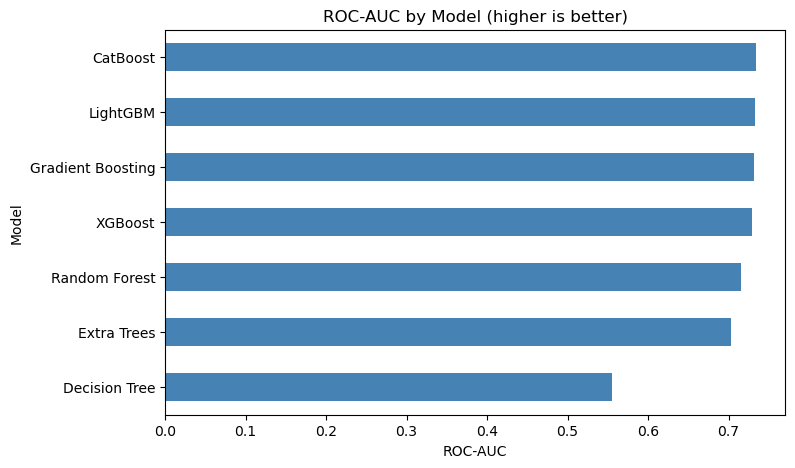

In [28]:
results_df.set_index("Model")["ROC-AUC"].sort_values().plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.title("ROC-AUC by Model (higher is better)")
plt.xlabel("ROC-AUC")
plt.show()

In [29]:
best_by_auc = results_df.iloc[0]
best_by_f1  = results_df.sort_values("F1 Score", ascending=False).iloc[0]
best_by_recall = results_df.sort_values("Recall", ascending=False).iloc[0]

print("BEST MODEL (ROC-AUC) :", best_by_auc["Model"], "->", round(best_by_auc["ROC-AUC"], 4))
print("Best F1 Score        :", best_by_f1["Model"], "->", round(best_by_f1["F1 Score"], 4))
print("Best Recall          :", best_by_recall["Model"], "->", round(best_by_recall["Recall"], 4))

BEST MODEL (ROC-AUC) : CatBoost -> 0.7333
Best F1 Score        : Decision Tree -> 0.2087
Best Recall          : Decision Tree -> 0.2176


In [30]:
best_name = best_by_auc["Model"]

print("Classification report for:", best_name)
print(classification_report(y_val, predictions[best_name], target_names=["Fully Paid", "Charged Off"]))

Classification report for: CatBoost
              precision    recall  f1-score   support

  Fully Paid       0.80      0.95      0.87     50055
 Charged Off       0.19      0.05      0.08     12774

    accuracy                           0.77     62829
   macro avg       0.50      0.50      0.47     62829
weighted avg       0.67      0.77      0.71     62829



In [31]:
best_name = best_by_f1["Model"]

print("Classification report for:", best_name)
print(classification_report(y_val, predictions[best_name], target_names=["Fully Paid", "Charged Off"]))

Classification report for: Decision Tree
              precision    recall  f1-score   support

  Fully Paid       0.80      0.78      0.79     50055
 Charged Off       0.20      0.22      0.21     12774

    accuracy                           0.66     62829
   macro avg       0.50      0.50      0.50     62829
weighted avg       0.67      0.66      0.67     62829



In [32]:
best_name = best_by_recall["Model"]

print("Classification report for:", best_name)
print(classification_report(y_val, predictions[best_name], target_names=["Fully Paid", "Charged Off"]))

Classification report for: Decision Tree
              precision    recall  f1-score   support

  Fully Paid       0.80      0.78      0.79     50055
 Charged Off       0.20      0.22      0.21     12774

    accuracy                           0.66     62829
   macro avg       0.50      0.50      0.50     62829
weighted avg       0.67      0.66      0.67     62829



In [ ]:
best_name = best_by_f1["Model"]

best_model = models[best_name]
import joblib

joblib.dump(best_model, )

FileNotFoundError: [Errno 2] No such file or directory: '/Users/shanigarapusheshanth/Desktop/SDC/MODELS/risk_prediction.joblib'

In [34]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

                                Feature  Importance
2                              int_rate   20.755757
4                            annual_inc    7.964135
5                                   dti    7.717014
11                            revol_bal    6.682354
1                                  term    6.548255
12                           revol_util    5.514027
0                             loan_amnt    5.508800
13                            total_acc    5.251149
3                           installment    4.961766
9                              open_acc    4.732251
7                        fico_range_low    4.213564
8                       fico_range_high    1.842077
15                              grade_C    1.749348
20              home_ownership_MORTGAGE    1.437589
22                  home_ownership_RENT    1.415417
6                           delinq_2yrs    1.382473
10                              pub_rec    1.335423
46                      emp_length_10.0    1.040156
24         v

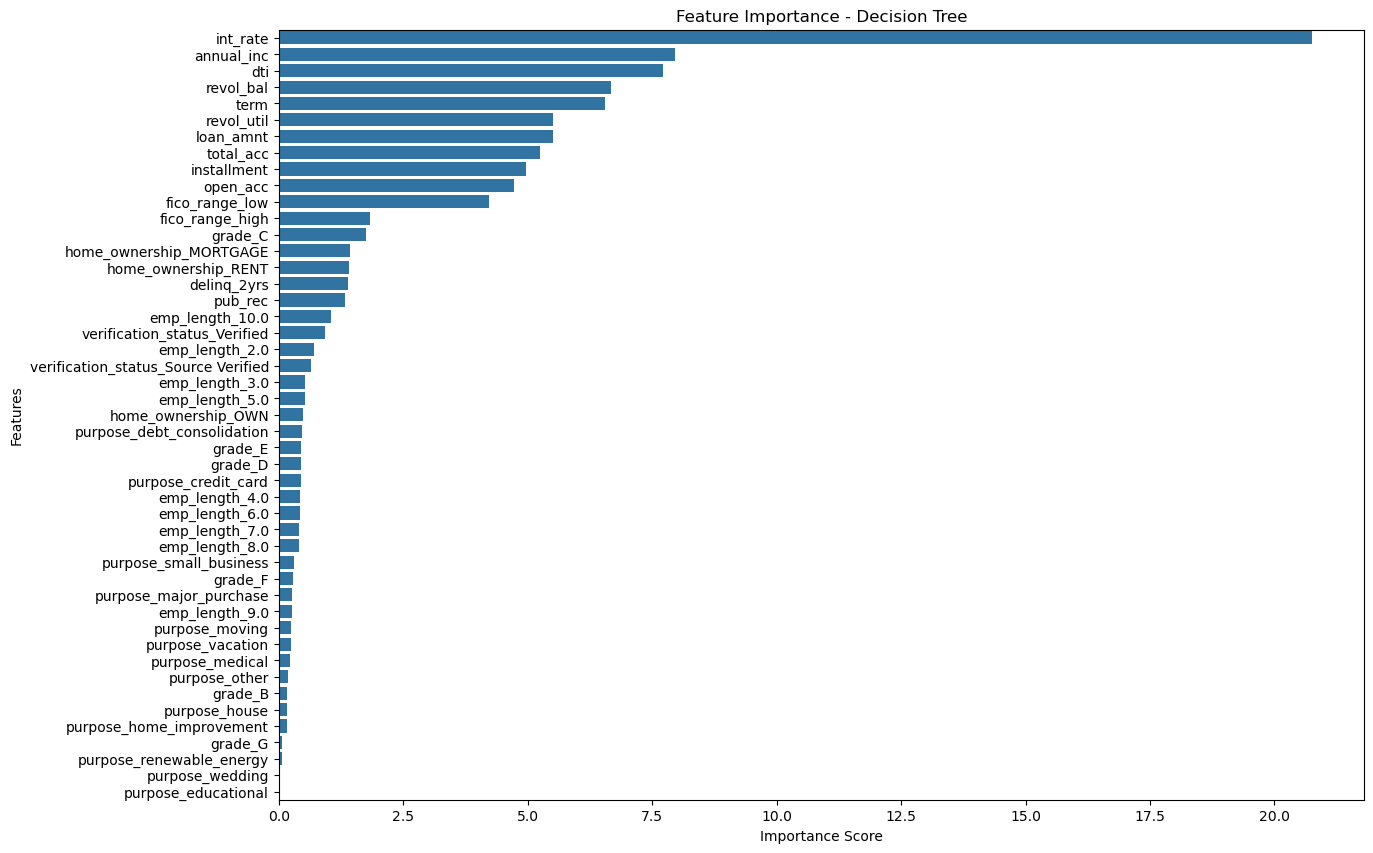

In [36]:
plt.figure(figsize=(14, 10))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Decision Tree")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

In [41]:
from sklearn.tree import export_text

tree_rules = export_text(
    best_model,
    feature_names=list(X_train.columns),
    max_depth=4
)

print(tree_rules)

|--- int_rate <= 13.09
|   |--- int_rate <= 9.62
|   |   |--- int_rate <= 7.69
|   |   |   |--- int_rate <= 6.58
|   |   |   |   |--- fico_range_low <= 722.50
|   |   |   |   |   |--- truncated branch of depth 28
|   |   |   |   |--- fico_range_low >  722.50
|   |   |   |   |   |--- truncated branch of depth 34
|   |   |   |--- int_rate >  6.58
|   |   |   |   |--- home_ownership_MORTGAGE <= 0.50
|   |   |   |   |   |--- truncated branch of depth 40
|   |   |   |   |--- home_ownership_MORTGAGE >  0.50
|   |   |   |   |   |--- truncated branch of depth 32
|   |   |--- int_rate >  7.69
|   |   |   |--- term <= 48.00
|   |   |   |   |--- home_ownership_MORTGAGE <= 0.50
|   |   |   |   |   |--- truncated branch of depth 45
|   |   |   |   |--- home_ownership_MORTGAGE >  0.50
|   |   |   |   |   |--- truncated branch of depth 42
|   |   |   |--- term >  48.00
|   |   |   |   |--- fico_range_low <= 722.50
|   |   |   |   |   |--- truncated branch of depth 30
|   |   |   |   |--- fico_range_l

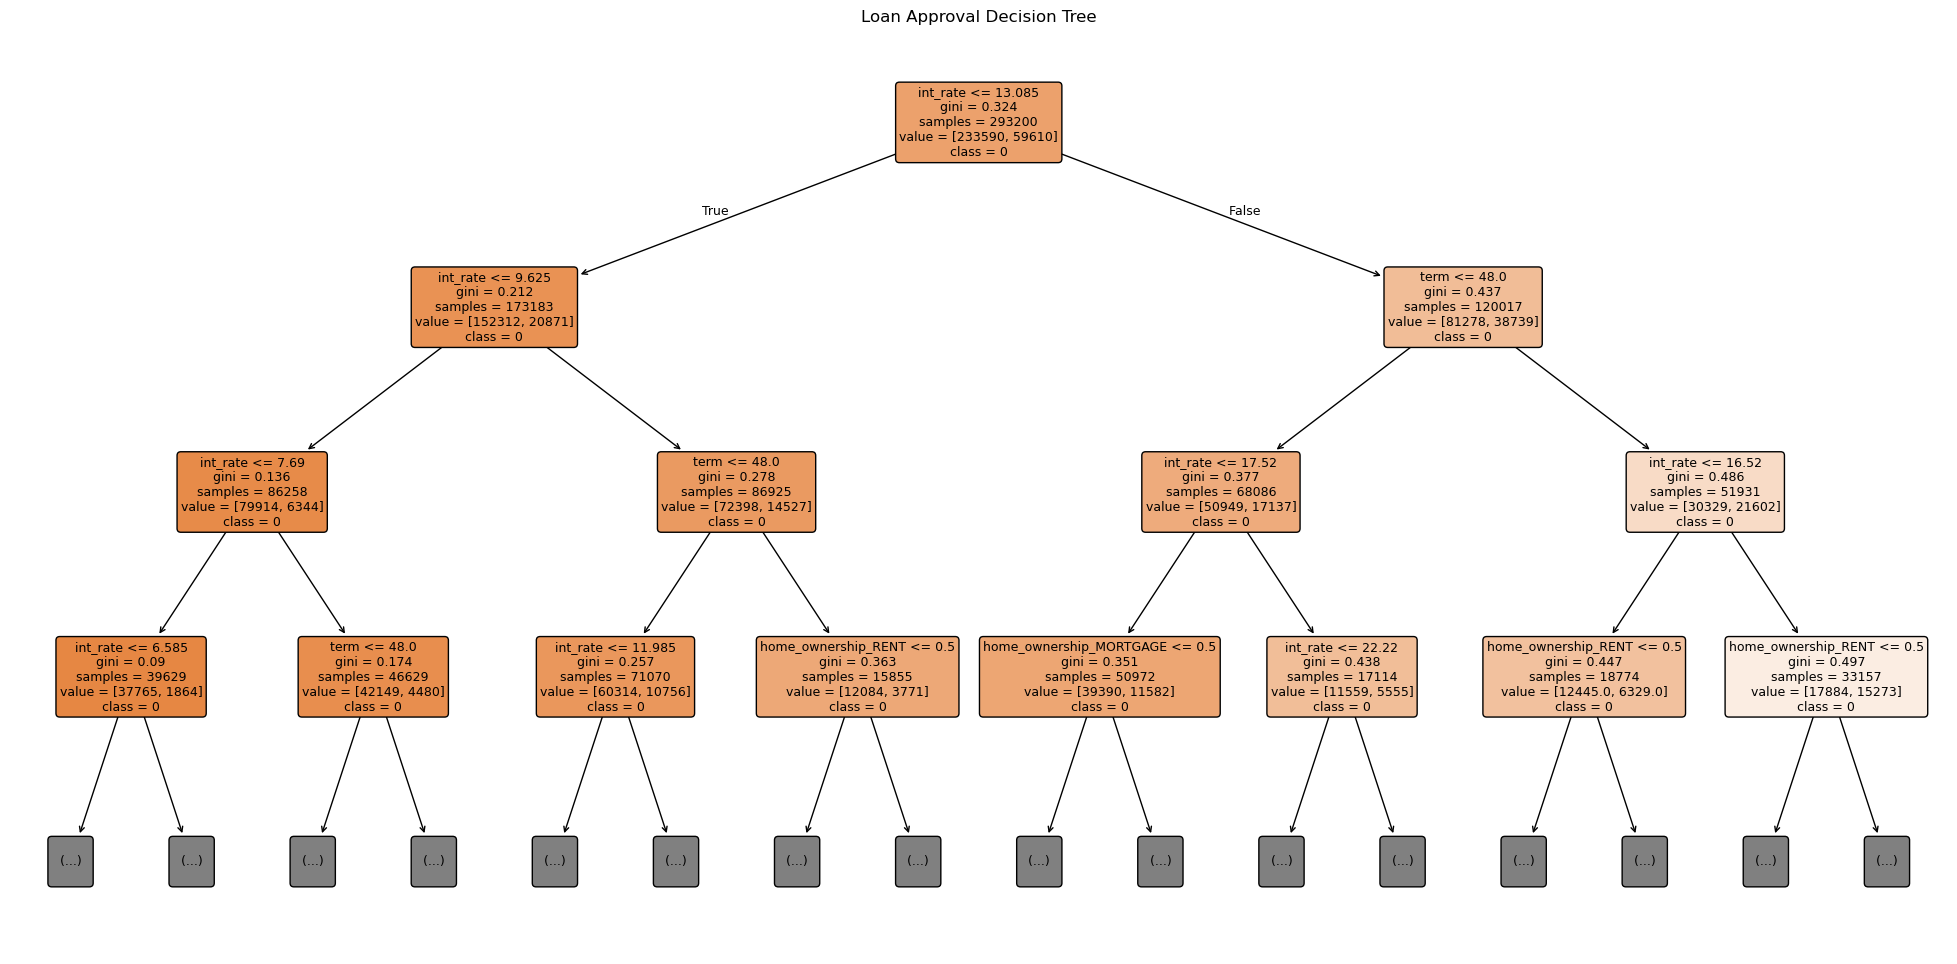

In [47]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(25, 12))

plot_tree(
    best_model,
    feature_names=X_train.columns.tolist(),
    class_names=[str(c) for c in best_model.classes_],
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Loan Approval Decision Tree")
plt.show()

In [48]:
!pip install shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 544.4/544.4 kB 3.1 MB/s  0:00:0036m-:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [shap]


In [3]:
import joblib
best_model=joblib.load("/Users/shanigarapusheshanth/Desktop/SDC/PROJECT 1/MODELS/risk_prediction.joblib")
